In [26]:
n=19
g=1
mu=0
T=1000
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.optimize import root
def simulate1(n,X0=-1,Nt=2000,tf=1000,g=1.0,mu=0.0,flag_display=False):
    """
    Simulation code for part 1
    Input:
        n: number of ODEs
        X0: initial condition if n-element numpy array. If X0 is an integer, the code will set 
        the initial condition (otherwise an array is expected).
        Nt: number of time steps
        tf: final time
        g,mu: model parameters
        flag_display: will generate a contour plot displaying results if True
    Output:
    t,x: numpy arrays containing times and simulation results
    """

    def model(t, X, n, g, mu):
        """
        Defines the system of ODEs 
        
        Input:
        - t: time 
        - X: array of variables [x_0, x_1, ..., x_{n-1}]
        - g, mu: scalar model parameters
        - n: number of ODEs (size of the system)
         
        Returns:
        - dXdt: array of derivatives [dx_0/dt, dx_1/dt, ..., dx_{n-1}/dt]
        """
        dXdt = np.zeros(n)
        dXdt[0] = X[0]*(1-g*X[-2]-X[0]-g*X[1]+mu*X[-3])
        dXdt[1] = X[1]*(1-g*X[-1]-X[1]-g*X[2])
        dXdt[2:n-1] = X[2:n-1]*(1-g*X[0:n-3]-X[2:n-1]-g*X[3:n])
        dXdt[-1] = X[-1]*(1-g*X[-3]-X[-1]-g*X[0])
        return dXdt

    # Parameters
    t_span = (0, tf)  # Time span for the integration
    if type(X0)==int: #(modified from original version)
        X0 = 1/(2*g+1)+0.001*np.random.rand(n)  # Random initial conditions, modify if needed

    # Solve the system
    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method='BDF',rtol=1e-10,atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt)  # Times to evaluate the solution
    )

    t,x = solution.t,solution.y #(in original version of code this line was inside if-block below)
    if flag_display:
        # Plot the solution
        plt.contour(t,np.arange(n),x,20)
        plt.xlabel('t') #(corrected axis labels)
        plt.ylabel('i')
    return t,x

import numpy as np
from scipy.optimize import root


def part1q1a(n, g, mu, T):
    """Part 1, question 1 (a)
    Use the variable inputs if/as needed.
    Input:
    n: number of ODEs
    g,mu: model parameters
    T: time at which perturbation energy ratio should be maximized

    Output:
    xbar: n-element array containing non-trivial equilibrium solution
    xtilde0: n-element array corresponding to computed initial condition
    eratio: computed maximum perturbation energy ratio
    """
    xbar = np.zeros(n)
    xtilde0 = np.zeros(n)
    eratio = 0.0

    def model(X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    eventus = root(model, np.ones(n), method="krylov", args=(n, g, mu))
    x_bar = eventus.x

    B = np.zeros([n, n])
    for i in range(2, n - 1):
        B[i, i] = -1
        B[i, i - 2] = -g
        B[i, i + 1] = -g

    B[0, 0] = -1
    B[0, n - 2] = -g
    B[0, 1] = -g
    B[0, n - 3] = mu

    B[1, 1] = -1
    B[1, n - 1] = -g
    B[1, 2] = -g

    B[n - 1, n - 1] = -1
    B[n - 1, n - 3] = -g
    B[n - 1, 0] = -g

    M = np.zeros([n, n])

    for i in range(n):
        M[i, i] = 1 + np.matmul(B[i, :], x_bar)

    for i in range(n):
        for j in range(n):
            M[i, j] += B[i, j] * x_bar[i]

    matM = scipy.linalg.expm(M*T)


    eigenvalores, eigenvectores = np.linalg.eig(matM)
    max_eigenvalue_index = np.argmax(np.real(eigenvalores))
    max_ratio = np.real(eigenvalores[max_eigenvalue_index])

    xbar = x_bar

    xtilde0 = eigenvectores[:, max_eigenvalue_index]

    eratio = max_ratio
    return xbar, xtilde0, eratio

In [27]:
def figuram_designare(n, g, mu, Nt, tf):
    t, X = simulate1(n=n, X0=-1, tf=T, g=g, mu=mu, flag_display=False)

    longitudo = len(t)
    t = t[int(longitudo/2):]
    X = X[:, int(longitudo / 2):]

    
    plt.figure(figsize=(12, 6))
    for i in range(n):
        plt.plot(t, X[i], label=f"x_{i}")
    plt.xlabel("Time")
    plt.ylabel("x values")
    plt.title(f"Time Evolution for n={n}, g={g}, mu={mu}")
    plt.grid(True)
    plt.show()



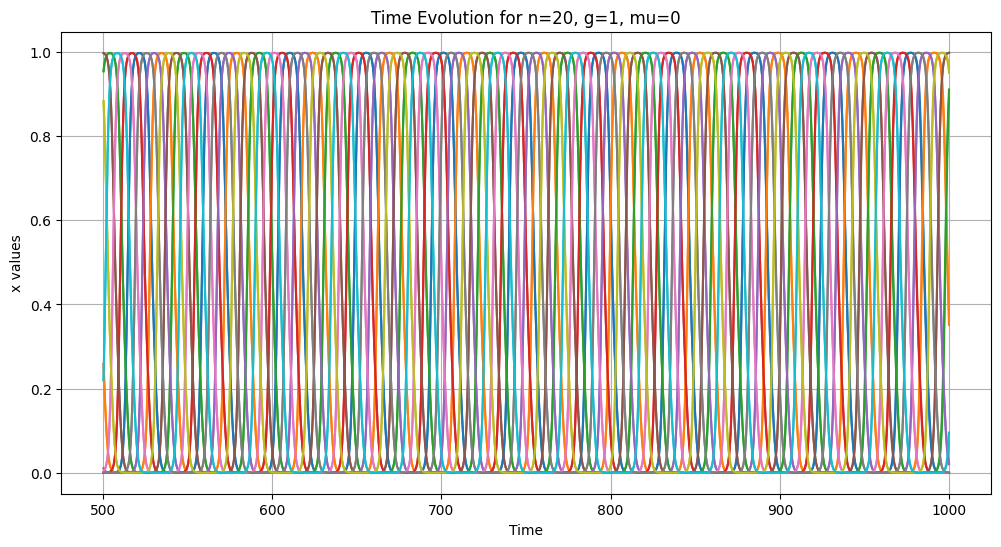

In [28]:
figuram_designare(20, g=1, mu=0, Nt=1000, tf=500)

In [46]:
def part1q2():
    """Part 1, question 2:
    Add input/output if/as needed.
    """

    # add code here
    def figuram_designare(n, g, mu, T, seco):
        t, X = simulate1(n=n, X0=-1, tf=T, g=g, mu=mu, flag_display=False)
        t = t[seco:]
        X = X[:, seco:]

        plt.figure(figsize=(12, 6))
        for i in range(n):
            plt.plot(t, X[i], label=f"x_{i}")
        plt.xlabel("Time")
        plt.ylabel("x values")
        plt.title(f"Time Evolution for n={n}, g={g}, mu={mu}")
        plt.grid(True)
        plt.show()

        for i in range(n):
            autocorr = np.correlate(
                X[i] - np.mean(X[i]), X[i] - np.mean(X[i]), mode="full"
            )
            autocorr /= autocorr[len(X[i]) - 1]  # Normalize
            lag = np.arange(-len(X[i]) + 1, len(X[i]))
            plt.plot(lag, autocorr, label=f"x_{i}")

        plt.xlabel("Lag")
        plt.ylabel("Autocorrelation")
        plt.title(f"Autocorrelation for n={n}, g={g}, mu={mu}")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    figuram_designare(n=9, g=1, mu=0, T=500, seco=900)
    figuram_designare(n=20, g=1, mu=0, T=1000, seco=900)
    figuram_designare(n=59, g=1, mu=0, T=1000, seco=900)

    return None  # modify if needed

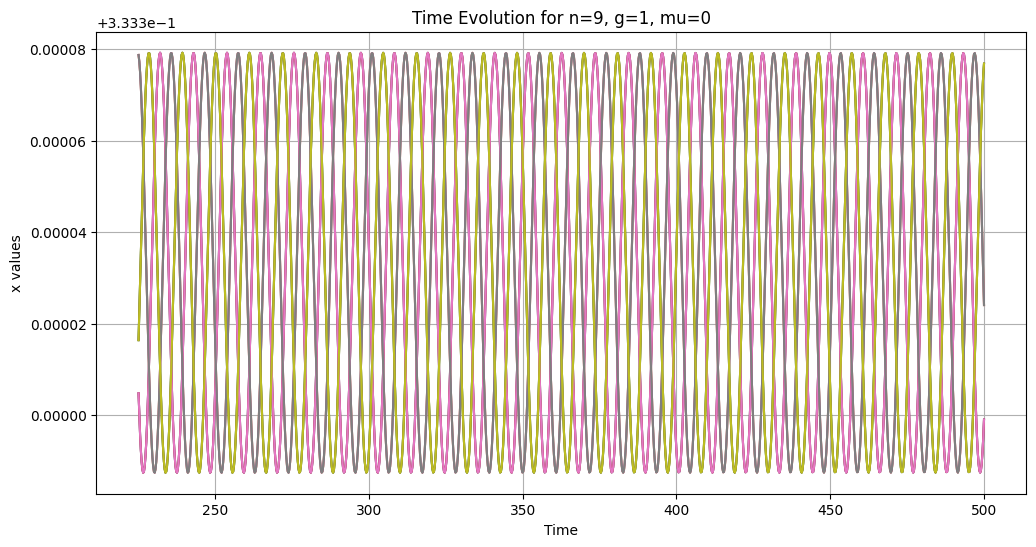

In [ ]:
def figuram_designare(n, g, mu, T, seco):
        t, X = simulate1(n=n, X0=-1, tf=T, g=g, mu=mu, flag_display=False)
        t = t[seco:]
        X = X[:, seco:]

        plt.figure(figsize=(12, 6))
        for i in range(n):
            plt.plot(t, X[i], label=f"x_{i}")
        plt.xlabel("Time")
        plt.ylabel("x values")
        plt.title(f"Time Evolution for n={n}, g={g}, mu={mu}")
        plt.grid(True)
        plt.show()

figuram_designare(n=9, g=1, mu=0, T=1000, seco=900)

In [40]:
X.shape

(19, 1800)

part1q2():

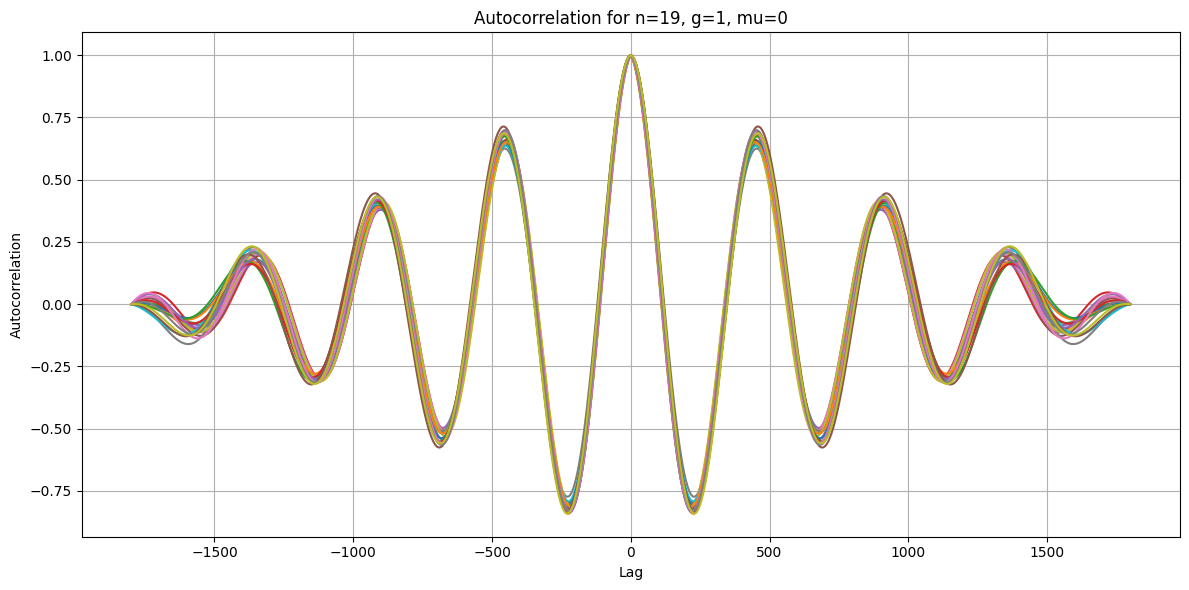

In [ ]:
import matplotlib.pyplot as plt
n = 
t, X = simulate1(n=n, X0=-1, tf=T, g=g, mu=mu, flag_display=False)
transient_cutoff = int(0.1 * len(t))
t = t[transient_cutoff:]
X = X[:, transient_cutoff:]
plt.figure(figsize=(12, 6))
for i in range(n):
    autocorr = np.correlate(
        X[i] - np.mean(X[i]), X[i] - np.mean(X[i]), mode="full"
    )
    autocorr /= autocorr[len(X[i]) - 1]  # Normalize
    lag = np.arange(-len(X[i]) + 1, len(X[i]))
    plt.plot(lag, autocorr, label=f"x_{i}")

plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.title(f"Autocorrelation for n={n}, g={g}, mu={mu}")
plt.grid(True)
plt.tight_layout()
plt.show()

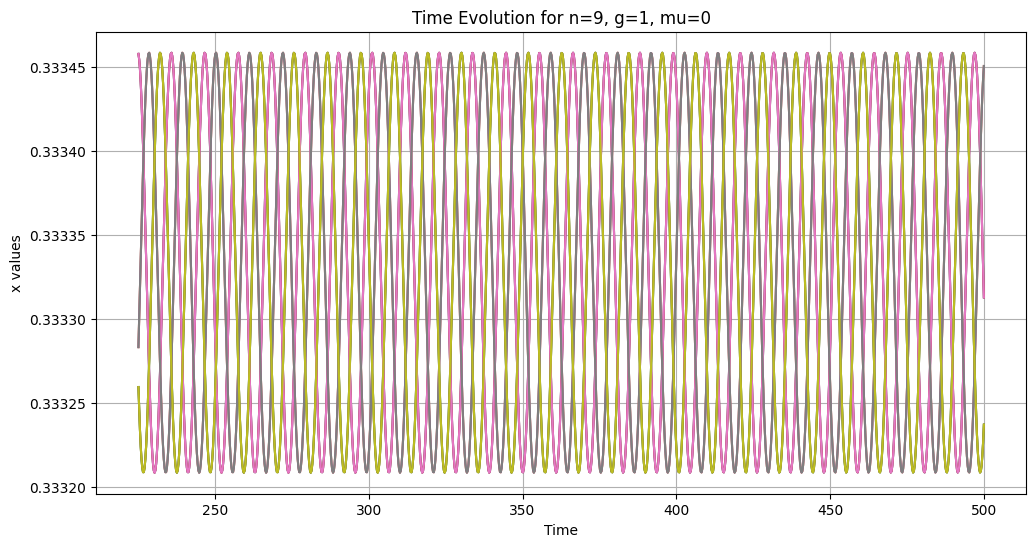

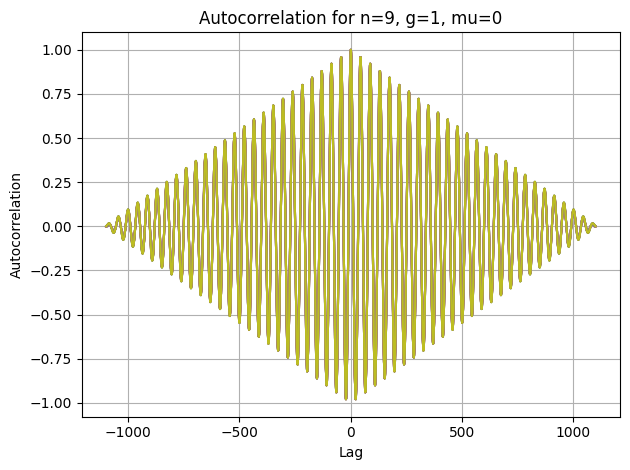

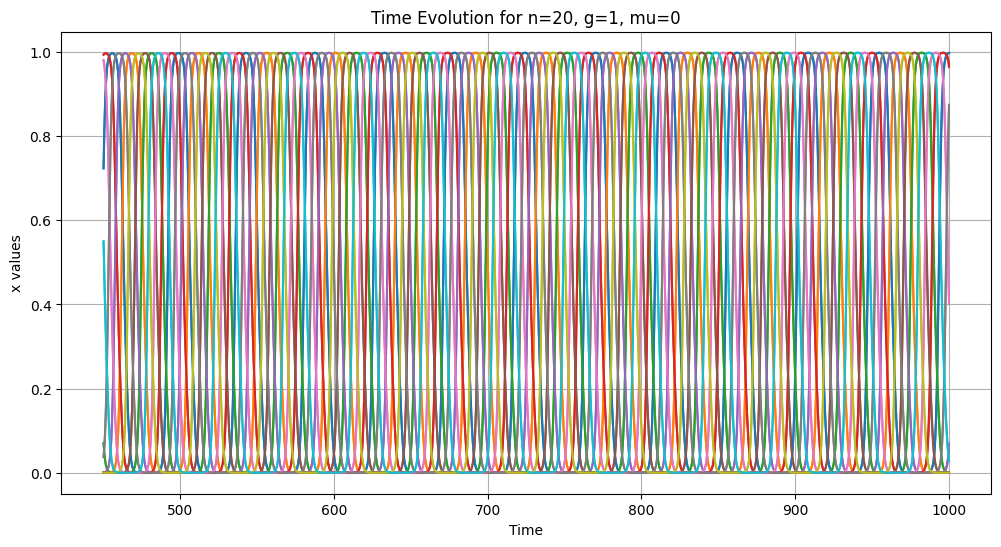

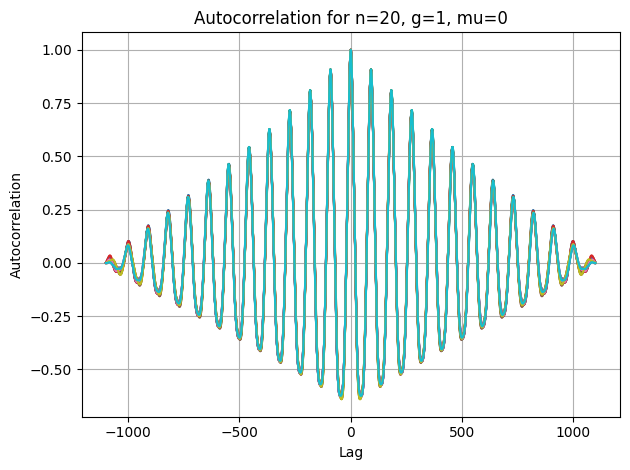

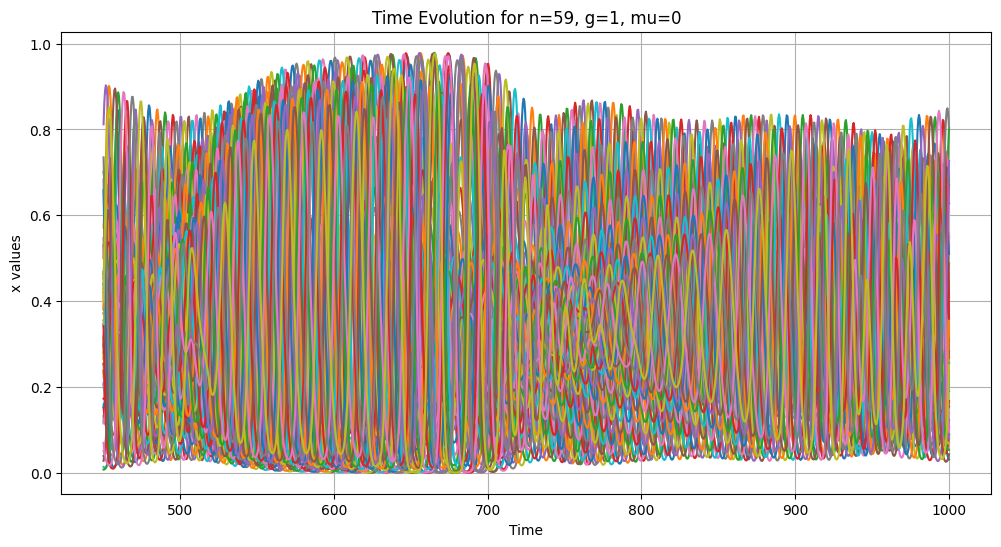

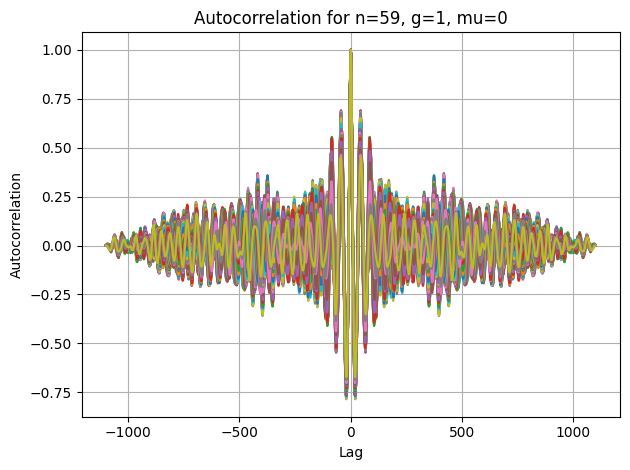

In [47]:
part1q2()

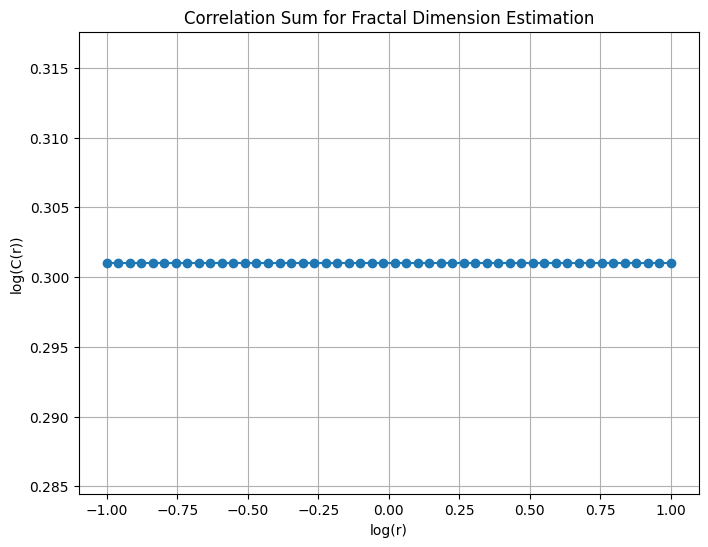

Estimated Correlation Dimension: 0.0


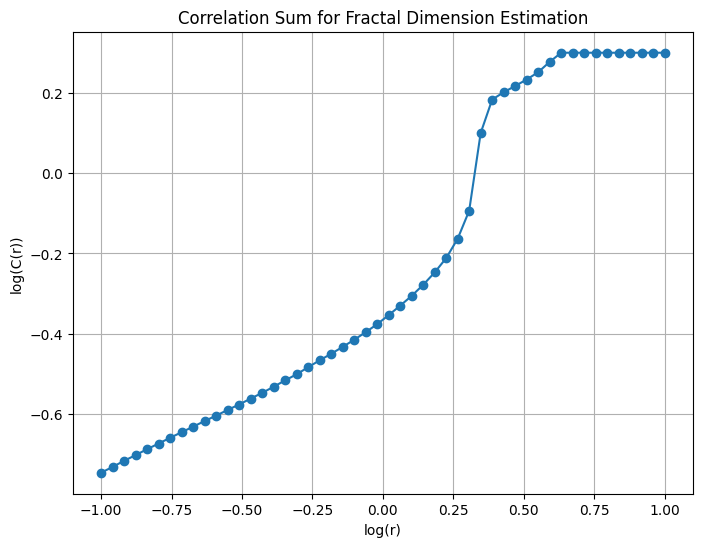

Estimated Correlation Dimension: 1.051197848366645


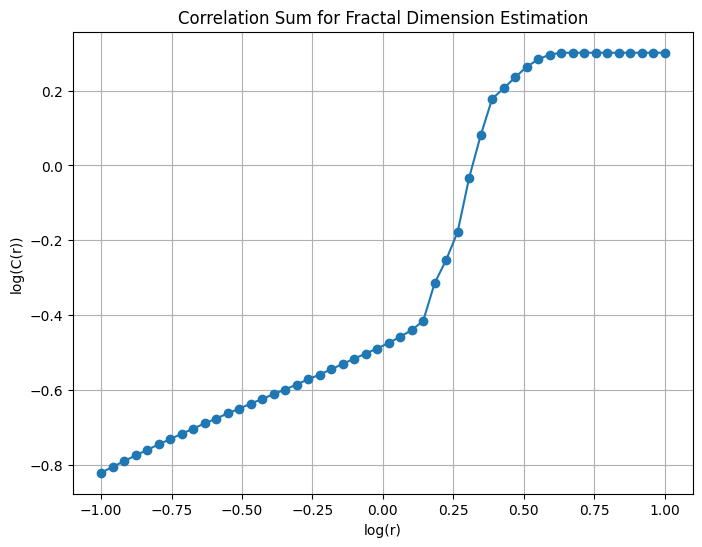

Estimated Correlation Dimension: 1.1163521305626138


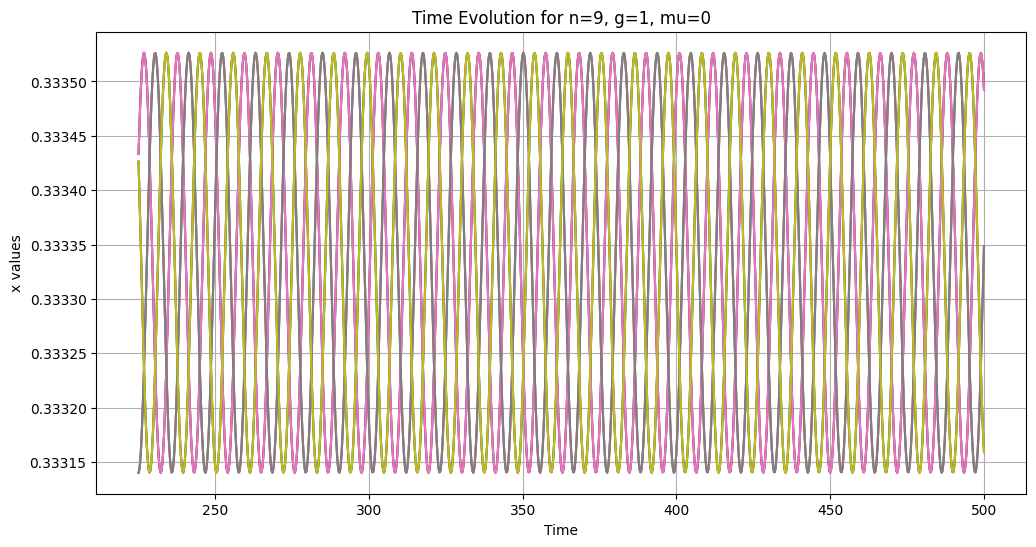

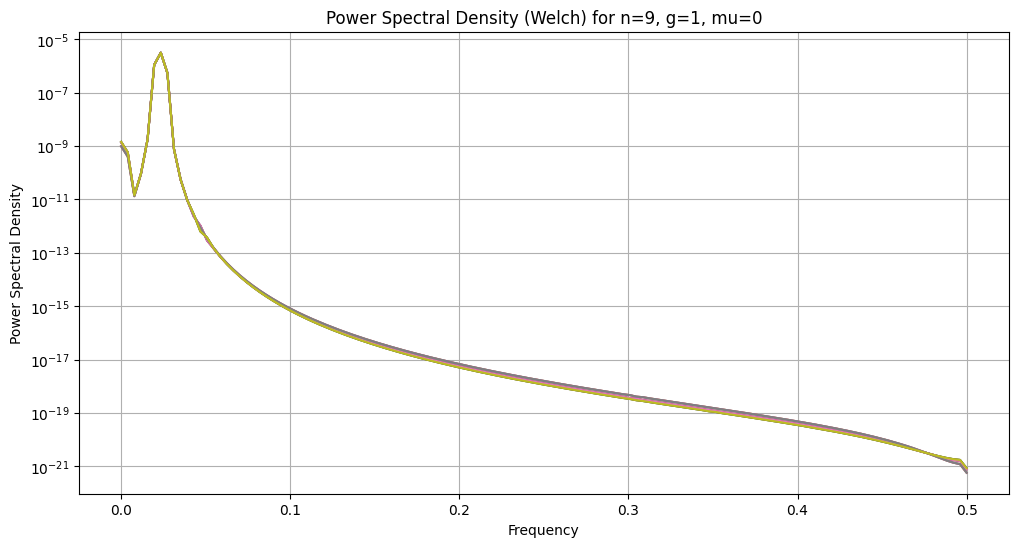

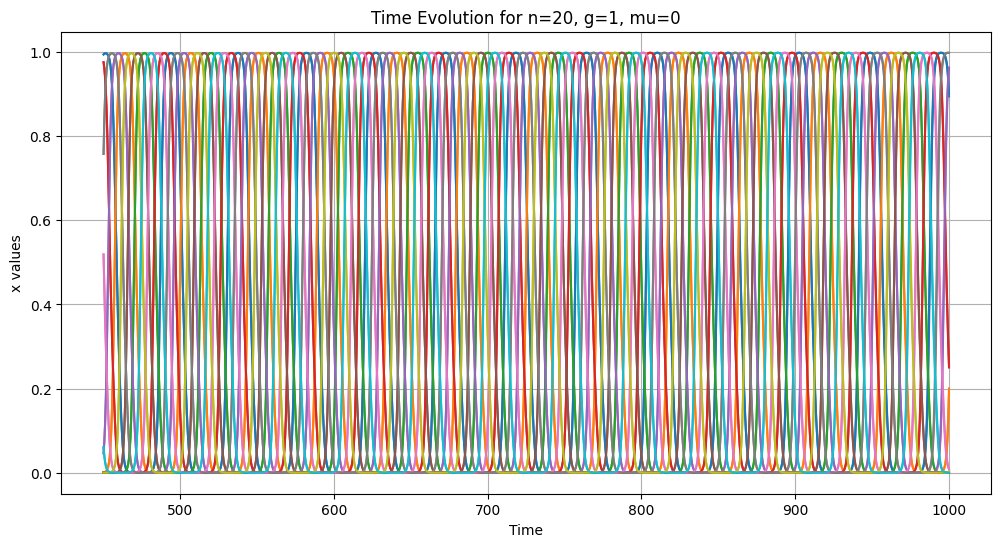

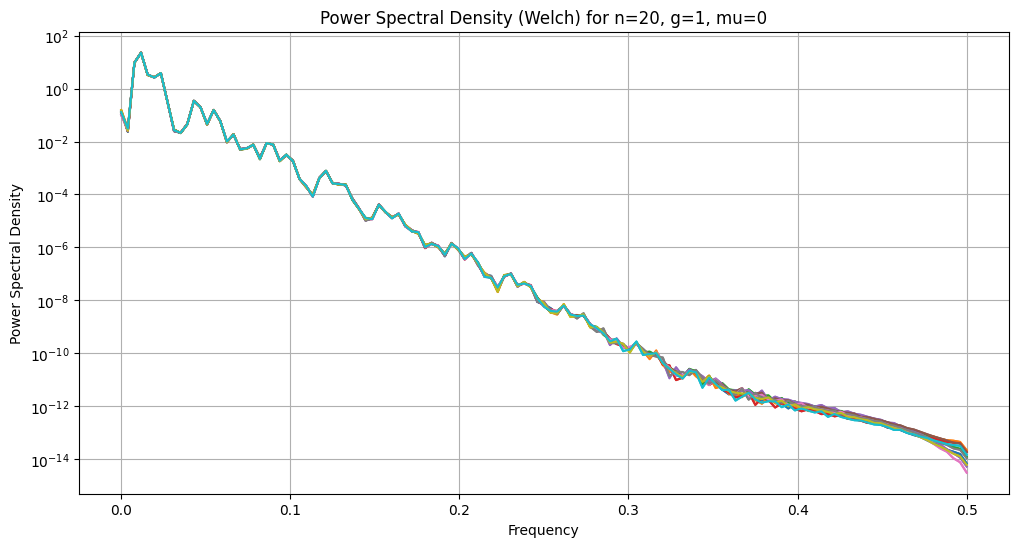

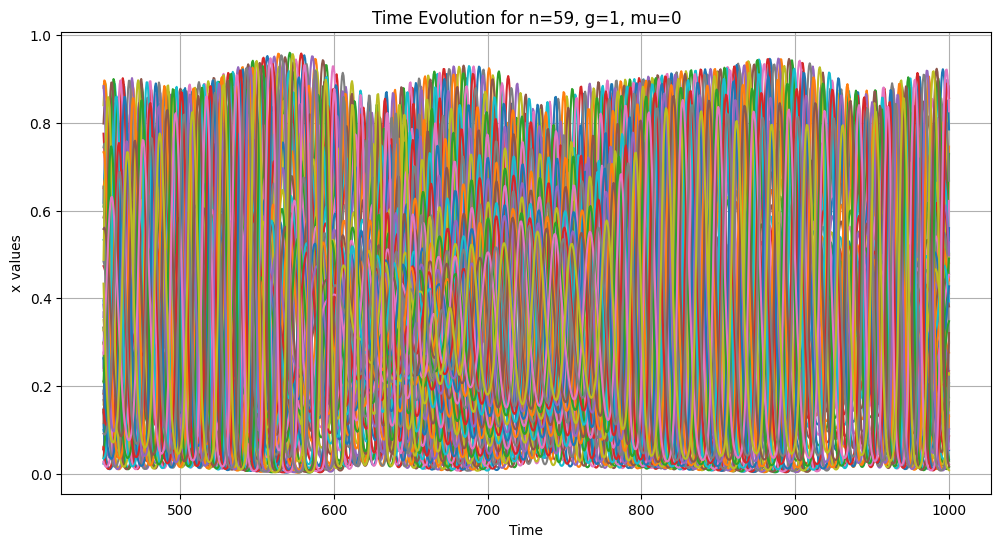

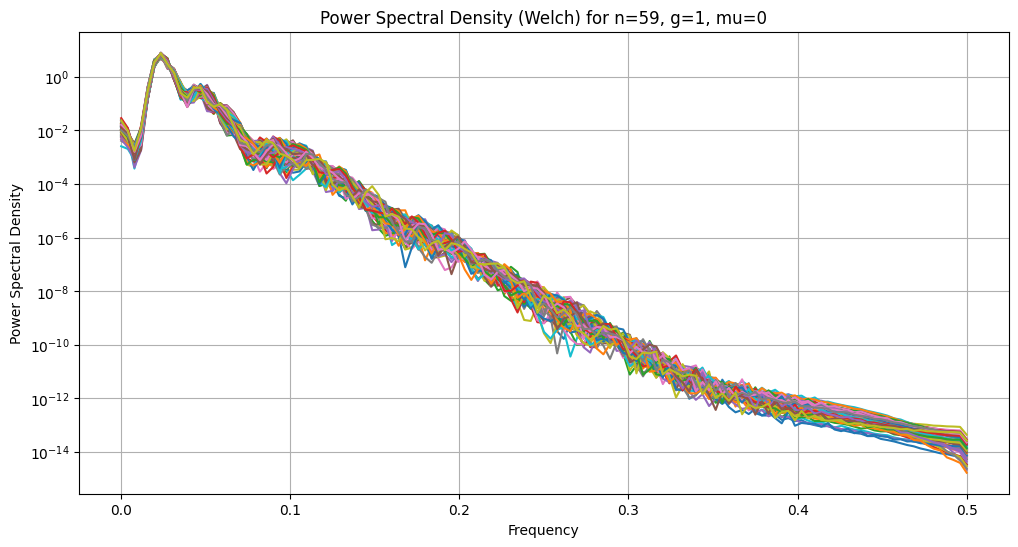

In [98]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import welch


def simulate1(n, X0=-1, Nt=2000, tf=1000, g=1.0, mu=0.0, flag_display=False):
    def model(t, X, n, g, mu):
        dXdt = np.zeros(n)
        dXdt[0] = X[0] * (1 - g * X[-2] - X[0] - g * X[1] + mu * X[-3])
        dXdt[1] = X[1] * (1 - g * X[-1] - X[1] - g * X[2])
        dXdt[2 : n - 1] = X[2 : n - 1] * (
            1 - g * X[0 : n - 3] - X[2 : n - 1] - g * X[3:n]
        )
        dXdt[-1] = X[-1] * (1 - g * X[-3] - X[-1] - g * X[0])
        return dXdt

    t_span = (0, tf)
    if type(X0) == int:
        X0 = 1 / (2 * g + 1) + 0.001 * np.random.rand(n)

    solution = solve_ivp(
        fun=model,
        t_span=t_span,
        y0=X0,
        args=(n, g, mu),
        method="BDF",
        rtol=1e-10,
        atol=1e-10,
        t_eval=np.linspace(t_span[0], t_span[1], Nt),
    )

    t, x = solution.t, solution.y
    if flag_display:
        plt.contour(t, np.arange(n), x, 20)
        plt.xlabel("t")
        plt.ylabel("i")

    return t, x


def part1q2():
    """Part 1, question 2 with Welch method for Power Spectral Density"""

    def figuram_designare(n, g, mu, T, seco):
        t, X = simulate1(n=n, X0=-1, tf=T, g=g, mu=mu, flag_display=False)
        t = t[seco:]
        X = X[:, seco:]

        # Plotting Time Evolution
        plt.figure(figsize=(12, 6))
        for i in range(n):
            plt.plot(t, X[i], label=f"x_{i}")
        plt.xlabel("Time")
        plt.ylabel("x values")
        plt.title(f"Time Evolution for n={n}, g={g}, mu={mu}")
        plt.grid(True)
        plt.show()

        # Plotting Power Spectral Density using Welch method
        plt.figure(figsize=(12, 6))
        for i in range(n):
            # Use Welch's method for Power Spectral Density estimation
            f, Pxx = welch(X[i], fs=1.0, nperseg=256, noverlap=128)
            plt.semilogy(f, Pxx, label=f"x_{i}")

        plt.xlabel("Frequency")
        plt.ylabel("Power Spectral Density")
        plt.title(f"Power Spectral Density (Welch) for n={n}, g={g}, mu={mu}")
        plt.grid(True)
        plt.show()

    # Function to create time-delay embedding for each vector
    def create_time_delay_embedding(data, m, tau):
        N = len(data)
        embedded = np.array([data[i : i + m * tau : tau] for i in range(N - (m - 1) * tau)])
        return embedded

    # Function to compute the correlation sum using KDTree
    def correlation_sum_with_kdtree(embedded_data, r):
        N = len(embedded_data)

        # Ensure that embedded_data is a 2D array (N, m), where each row is a vector
        embedded_data = np.vstack(embedded_data)

        # Build the KDTree for fast nearest neighbor search
        tree = KDTree(embedded_data)

        # Count the number of pairs where the distance is less than r (ignoring self-pairs)
        count = 0
        for i in range(N):
            # Query for all points within radius r (excluding the point itself)
            count += len(tree.query_ball_point(embedded_data[i], r)) - 1

        return 2 * count / (N * (N - 1))  # Normalize by number of pairs

    # Function to estimate the fractal dimension using correlation sum
    def estimate_fractal_dimension(
        data, m=3, tau=1, r_min=0.1, r_max=10, num_r=50, downsample_factor=10
    ):
        # Create time-delay embedding
        embedded_data = create_time_delay_embedding(data, m, tau)

        # Downsample the data to speed up computation (use every downsample_factor-th point)
        downsampled_data = embedded_data[::downsample_factor]

        # Ensure the embedded data is a 2D array for KDTree
        downsampled_data = np.vstack(downsampled_data)

        # Generate range of radii
        r_values = np.logspace(np.log10(r_min), np.log10(r_max), num_r)

        # Compute correlation sum for each radius using KDTree
        correlation_sums = []
        for r in r_values:
            correlation_sums.append(correlation_sum_with_kdtree(downsampled_data, r))

        # Plot the log-log plot of correlation sum
        plt.figure(figsize=(8, 6))
        plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
        plt.xlabel("log(r)")
        plt.ylabel("log(C(r))")
        plt.title("Correlation Sum for Fractal Dimension Estimation")
        plt.grid(True)
        plt.show()

        # Estimate the slope (correlation dimension) from the log-log plot
        p=len(r_values)
        ordo=[]
        for i in range(p-5):
            ordo.append(
                (correlation_sums[i + 5] - correlation_sums[i]) / (r_values[i + 5] - r_values[i])
            )

        # slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
        slope=max(ordo)
        print(f"Estimated Correlation Dimension: {slope}")

    t, X = simulate1(n=9, X0=-1, tf=500, Nt=10000, g=1, mu=0, flag_display=False)
    estimate_fractal_dimension(X.T, m=3, tau=1, downsample_factor=20) 

    t, X = simulate1(n=30, X0=-1, tf=500, Nt=10000, g=1, mu=0, flag_display=False)
    estimate_fractal_dimension(X.T, m=3, tau=1, downsample_factor=20)

    t, X = simulate1(n=59, X0=-1, tf=500, Nt=10000, g=1, mu=0, flag_display=False)
    estimate_fractal_dimension(X.T, m=3, tau=1, downsample_factor=20)

    # Example simulation for different system sizes and parameters
    figuram_designare(n=9, g=1, mu=0, T=500, seco=900)
    figuram_designare(n=20, g=1, mu=0, T=1000, seco=900)
    figuram_designare(n=59, g=1, mu=0, T=1000, seco=900)

    return None


# Call the function to perform the analysis
part1q2()

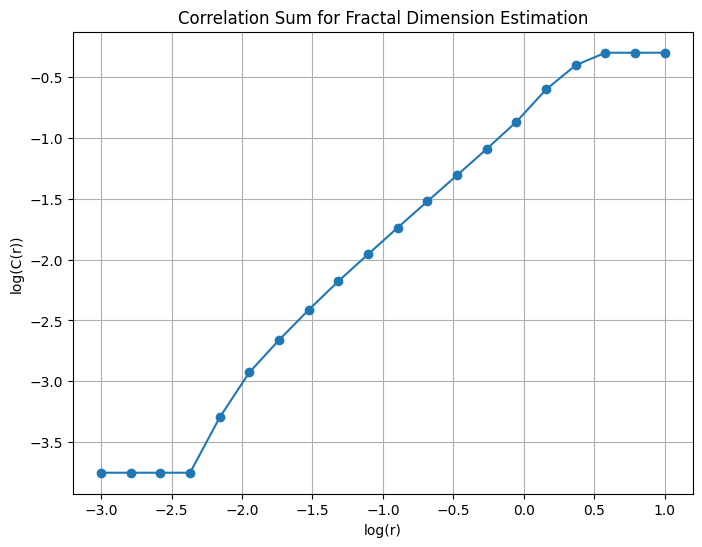

Estimated Fractal Dimension: 1.0223250981890073


In [50]:
import numpy as np
import matplotlib.pyplot as plt


# Function to create time-delay embedding for an n-dimensional time series
def create_time_delay_embedding(data, m, tau):
    N = len(data)
    embedded_data = np.array(
        [data[i : i + m * tau : tau] for i in range(N - (m - 1) * tau)]
    )
    return embedded_data


# Function to compute the correlation sum C(r)
def correlation_sum(embedded_data, r):
    N = len(embedded_data)
    count = 0
    # Iterate through all pairs (i, j) of points in the embedded space
    for i in range(N):
        for j in range(i + 1, N):
            # Calculate Euclidean distance between points
            distance = np.linalg.norm(embedded_data[i] - embedded_data[j])
            if distance < r:
                count += 1
    return count / (N * (N - 1))


# Function to compute and plot the fractal dimension using correlation sum
def estimate_fractal_dimension(data, m, tau):
    # Create the time-delay embedding
    embedded_data = create_time_delay_embedding(data, m, tau)

    # Define a range of r values (distances) for the correlation sum
    r_values = np.logspace(-3, 1, 20)
    correlation_sums = [correlation_sum(embedded_data, r) for r in r_values]

    # Plot the log-log graph of correlation sum vs. r
    plt.figure(figsize=(8, 6))
    plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum for Fractal Dimension Estimation")
    plt.grid(True)
    plt.show()

    # Estimate the fractal dimension from the slope of the log-log plot
    slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
    print(f"Estimated Fractal Dimension: {slope}")


# Example usage
# Simulate some data (e.g., a chaotic system or any time series)
np.random.seed(42)
data = np.sin(np.linspace(0, 100, 1000))  # Example sine wave data

# Estimate the fractal dimension
estimate_fractal_dimension(data, m=3, tau=5)

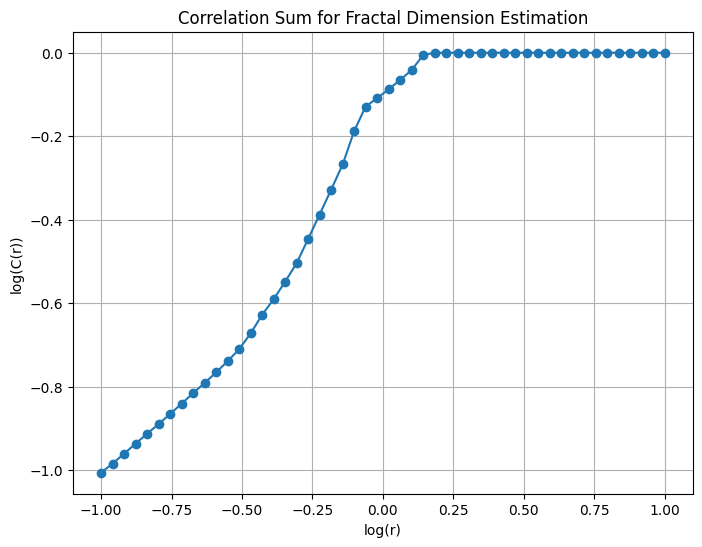

Estimated Correlation Dimension: 0.5844424952192859


In [57]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree


# Function to create time-delay embedding for each vector
def create_time_delay_embedding(vectors, m, tau):
    N, L = vectors.shape  # N: number of vectors, L: length of each vector
    embedded_data = []
    for vector in vectors:
        # Create time-delay embedding for each vector
        embedded_vector = np.array(
            [vector[i : i + m * tau : tau] for i in range(L - (m - 1) * tau)]
        )
        embedded_data.append(embedded_vector)
    return np.array(embedded_data)


# Function to compute the correlation sum efficiently using KD-Tree
def correlation_sum_with_kd_tree(embedded_data, r):
    N = len(embedded_data)

    # Convert the list of embedded vectors to a 2D array
    embedded_data_flat = embedded_data.reshape(-1, embedded_data.shape[-1])

    # Create KD-Tree for the embedded data
    tree = cKDTree(embedded_data_flat)

    # Count the number of pairs where the distance is less than r
    count = 0
    for point in embedded_data_flat:
        # Query the tree for all points within distance r of the current point
        count += len(tree.query_ball_point(point, r)) - 1  # Subtract the point itself

    return count / (N * (N - 1))  # Normalize by number of pairs


# Function to estimate the fractal dimension using correlation sum
def estimate_fractal_dimension(vectors, m=3, tau=1, r_min=0.1, r_max=10, num_r=50):
    # Create time-delay embedding
    embedded_data = create_time_delay_embedding(vectors, m, tau)

    # Flatten the data (if you want to treat all embedded vectors as a single entity for fractal dimension)
    flattened_data = embedded_data.reshape(-1, embedded_data.shape[-1])

    # Generate a range of radii
    r_values = np.logspace(np.log10(r_min), np.log10(r_max), num_r)

    # Compute correlation sum for each radius using KD-Tree
    correlation_sums = np.array(
        [correlation_sum_with_kd_tree(flattened_data, r) for r in r_values]
    )

    # Plot the log-log plot of correlation sum
    plt.figure(figsize=(8, 6))
    plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum for Fractal Dimension Estimation")
    plt.grid(True)
    plt.show()

    # Estimate the slope (correlation dimension) from the log-log plot
    slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
    print(f"Estimated Correlation Dimension: {slope}")


# Example usage with n vectors (each of length m)
t, X = simulate1(n=30, X0=-1, tf=500,Nt=100, g=1, mu=0, flag_display=False)
transient_cutoff = int(0.1 * len(t))
t = t[transient_cutoff:]
X = X[:, transient_cutoff:]
estimate_fractal_dimension(X.T, m=3, tau=1)

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# Lorenz system equations
def lorenz(t, state, sigma=10, beta=8 / 3, rho=28):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = x * (rho - z) - y
    dzdt = x * y - beta * z
    return [dxdt, dydt, dzdt]


# Function to compute the time-delay embedding of the system
def create_time_delay_embedding(data, m, tau):
    N = len(data)
    embedded = np.array([data[i : i + m * tau : tau] for i in range(N - (m - 1) * tau)])
    return embedded


# Function to compute the correlation sum
def correlation_sum(embedded_data, r):
    N = len(embedded_data)
    count = 0
    for i in range(N):
        for j in range(i + 1, N):
            dist = np.linalg.norm(embedded_data[i] - embedded_data[j])
            if dist < r:
                count += 1
    return 2 * count / (N * (N - 1))  # Normalize by the number of pairs


# Function to estimate the fractal dimension using correlation sum
def estimate_fractal_dimension(data, m=3, tau=1, r_min=0.1, r_max=10, num_r=50):
    # Create time-delay embedding
    embedded_data = create_time_delay_embedding(data, m, tau)

    # Generate range of radii
    r_values = np.logspace(np.log10(r_min), np.log10(r_max), num_r)

    # Compute correlation sum for each radius
    correlation_sums = [correlation_sum(embedded_data, r) for r in r_values]

    # Plot the log-log plot of correlation sum
    plt.figure(figsize=(8, 6))
    plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum for Fractal Dimension Estimation")
    plt.grid(True)
    plt.show()

    # Estimate the slope (correlation dimension) from the log-log plot
    slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
    print(f"Estimated Correlation Dimension: {slope}")


# Simulate the Lorenz system
def simulate_lorenz(tf=100.0, dt=0.01, initial_state=[1.0, 1.0, 1.0]):
    t_span = (0, tf)
    t_eval = np.arange(0, tf, dt)
    sol = solve_ivp(
        lorenz, t_span, initial_state, t_eval=t_eval, rtol=1e-10, atol=1e-10
    )
    return sol.t, sol.y


# Example usage
t, X = simulate_lorenz(tf=200.0, dt=0.01, initial_state=[1.0, 1.0, 1.0])

# Use a subset of data after transient to get the fractal dimension
transient_cutoff = int(0.1 * len(t))  # Discard first 10% of data to avoid transients
t = t[transient_cutoff:]
X = X[:, transient_cutoff:]

# Estimate the fractal dimension of the Lorenz system
estimate_fractal_dimension(X.T, m=3, tau=1)  # X.T to pass it as a list of vectors

KeyboardInterrupt: 

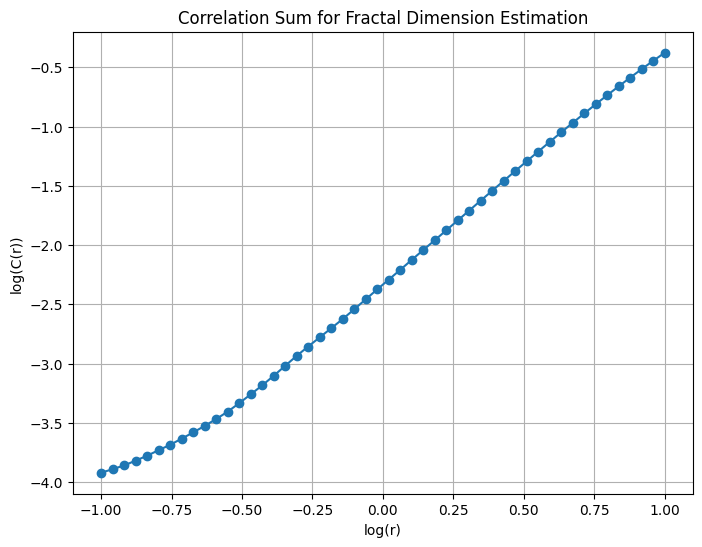

Estimated Correlation Dimension: 1.8835407378654299


In [61]:
# Function to create time-delay embedding for each vector
def create_time_delay_embedding(data, m, tau):
    N = len(data)
    embedded = np.array([data[i : i + m * tau : tau] for i in range(N - (m - 1) * tau)])
    return embedded


# Function to compute the correlation sum using KDTree
def correlation_sum_with_kdtree(embedded_data, r):
    N = len(embedded_data)

    # Ensure that embedded_data is a 2D array (N, m), where each row is a vector
    embedded_data = np.vstack(embedded_data)

    # Build the KDTree for fast nearest neighbor search
    tree = KDTree(embedded_data)

    # Count the number of pairs where the distance is less than r (ignoring self-pairs)
    count = 0
    for i in range(N):
        # Query for all points within radius r (excluding the point itself)
        count += len(tree.query_ball_point(embedded_data[i], r)) - 1

    return 2 * count / (N * (N - 1))  # Normalize by number of pairs


# Function to estimate the fractal dimension using correlation sum
def estimate_fractal_dimension(data, m=3, tau=1, r_min=0.1, r_max=10, num_r=50):
    # Create time-delay embedding
    embedded_data = create_time_delay_embedding(data, m, tau)

    # Ensure the embedded data is a 2D array for KDTree
    embedded_data = np.vstack(embedded_data)

    # Generate range of radii
    r_values = np.logspace(np.log10(r_min), np.log10(r_max), num_r)

    # Compute correlation sum for each radius using KDTree
    correlation_sums = []
    for r in r_values:
        correlation_sums.append(correlation_sum_with_kdtree(embedded_data, r))

    # Plot the log-log plot of correlation sum
    plt.figure(figsize=(8, 6))
    plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum for Fractal Dimension Estimation")
    plt.grid(True)
    plt.show()

    # Estimate the slope (correlation dimension) from the log-log plot
    slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
    print(f"Estimated Correlation Dimension: {slope}")


# Simulate the Lorenz system
def lorenz(t, state, sigma=10, beta=8 / 3, rho=28):
    x, y, z = state
    dxdt = sigma * (y - x)
    dydt = x * (rho - z) - y
    dzdt = x * y - beta * z
    return [dxdt, dydt, dzdt]


# Simulate Lorenz system numerically
def simulate_lorenz(tf=100.0, dt=0.01, initial_state=[1.0, 1.0, 1.0]):
    t_span = (0, tf)
    t_eval = np.arange(0, tf, dt)
    sol = solve_ivp(
        lorenz, t_span, initial_state, t_eval=t_eval, rtol=1e-10, atol=1e-10
    )
    return sol.t, sol.y


# Example usage
t, X = simulate_lorenz(tf=200.0, dt=0.01, initial_state=[1.0, 1.0, 1.0])

# Use a subset of data after transient to get the fractal dimension
transient_cutoff = int(0.1 * len(t))  # Discard first 10% of data to avoid transients
t = t[transient_cutoff:]
X = X[:, transient_cutoff:]

# Estimate the fractal dimension of the Lorenz system
estimate_fractal_dimension(X.T, m=3, tau=1)  # X.T to pass it as a list of vectors

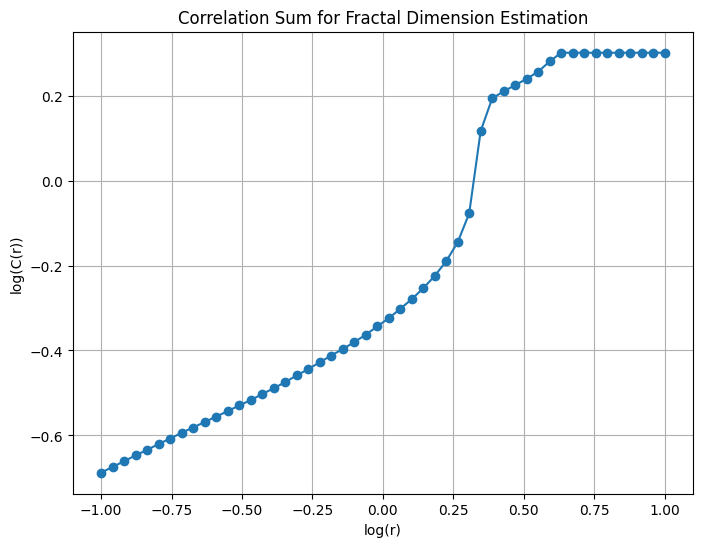

Estimated Correlation Dimension: 0.599216402552298


In [87]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import KDTree


# Function to create time-delay embedding for each vector
def create_time_delay_embedding(data, m, tau):
    N = len(data)
    embedded = np.array([data[i : i + m * tau : tau] for i in range(N - (m - 1) * tau)])
    return embedded


# Function to compute the correlation sum using KDTree
def correlation_sum_with_kdtree(embedded_data, r):
    N = len(embedded_data)

    # Ensure that embedded_data is a 2D array (N, m), where each row is a vector
    embedded_data = np.vstack(embedded_data)

    # Build the KDTree for fast nearest neighbor search
    tree = KDTree(embedded_data)

    # Count the number of pairs where the distance is less than r (ignoring self-pairs)
    count = 0
    for i in range(N):
        # Query for all points within radius r (excluding the point itself)
        count += len(tree.query_ball_point(embedded_data[i], r)) - 1

    return 2 * count / (N * (N - 1))  # Normalize by number of pairs


# Function to estimate the fractal dimension using correlation sum
def estimate_fractal_dimension(
    data, m=3, tau=1, r_min=0.1, r_max=10, num_r=50, downsample_factor=10
):
    # Create time-delay embedding
    embedded_data = create_time_delay_embedding(data, m, tau)

    # Downsample the data to speed up computation (use every downsample_factor-th point)
    downsampled_data = embedded_data[::downsample_factor]

    # Ensure the embedded data is a 2D array for KDTree
    downsampled_data = np.vstack(downsampled_data)

    # Generate range of radii
    r_values = np.logspace(np.log10(r_min), np.log10(r_max), num_r)

    # Compute correlation sum for each radius using KDTree
    correlation_sums = []
    for r in r_values:
        correlation_sums.append(correlation_sum_with_kdtree(downsampled_data, r))

    # Plot the log-log plot of correlation sum
    plt.figure(figsize=(8, 6))
    plt.plot(np.log10(r_values), np.log10(correlation_sums), marker="o")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum for Fractal Dimension Estimation")
    plt.grid(True)
    plt.show()

    # Estimate the slope (correlation dimension) from the log-log plot
    slope = np.polyfit(np.log10(r_values), np.log10(correlation_sums), 1)[0]
    print(f"Estimated Correlation Dimension: {slope}")


t, X = simulate1(n=30, X0=-1, tf=500, Nt=10000, g=1, mu=0, flag_display=False)



# Estimate the fractal dimension of the Lorenz system
estimate_fractal_dimension(
    X.T, m=3, tau=1, downsample_factor=20
)  # Downsample by a factor of 20 for efficiency

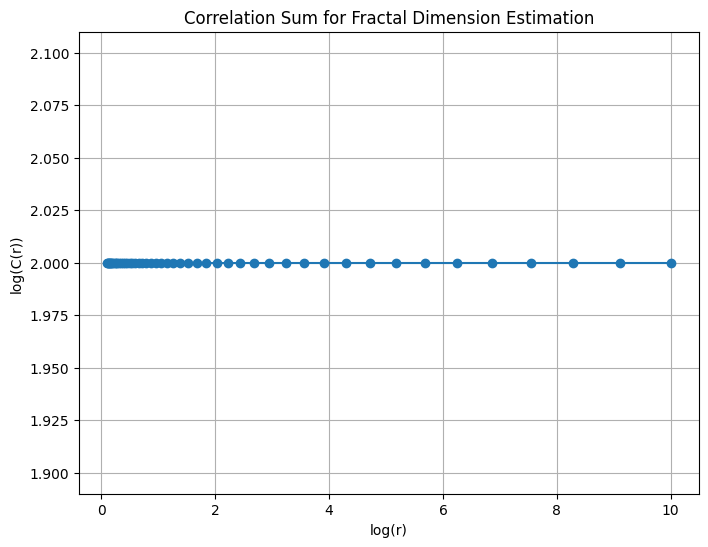

Estimated Correlation Dimension: 6.0377961595394775e-18


In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import KDTree
from scipy.integrate import solve_ivp




# Function to create time-delay embedding for each row of the matrix
def create_time_delay_embedding(matrix, m, tau):
    """
    Create time-delay embedding for each row of the matrix.

    Parameters:
    - matrix: (n, m) matrix, where n is the number of variables, and m is the time series length.
    - m: Embedding dimension.
    - tau: Time delay.

    Returns:
    - Embedded data: (n, k, m), where k is the number of embedded points per variable.
    """
    n, length = matrix.shape
    embedded_data = []
    for i in range(n):
        embedded = np.array(
            [matrix[i, j : j + m * tau : tau] for j in range(length - (m - 1) * tau)]
        )
        embedded_data.append(embedded)
    return np.vstack(embedded_data)


# Function to compute the correlation sum using KDTree
def correlation_sum_with_kdtree(embedded_data, r):
    N = len(embedded_data)
    # Build KDTree for fast nearest neighbor search
    tree = KDTree(embedded_data)
    # Count the number of pairs where the distance is less than r
    count = 0
    for i in range(N):
        count += (
            len(tree.query_ball_point(embedded_data[i], r)) - 1
        )  # Exclude self-pairs
    return 2 * count / (N * (N - 1))  # Normalize by number of pairs


# Function to estimate the fractal dimension using correlation sum
def estimate_fractal_dimension(
    matrix, m=3, tau=1, r_min=0.1, r_max=10, num_r=50, downsample_factor=10
):
    """
    Estimate the fractal dimension for an (n, m) matrix.
    """
    # Create time-delay embedding for the matrix
    embedded_data = create_time_delay_embedding(matrix, m, tau)

    # Downsample the data to improve efficiency
    embedded_data = embedded_data[::downsample_factor]

    # Generate a range of radii
    r_values = np.logspace(np.log10(r_min), np.log10(r_max), num_r)

    # Compute correlation sum for each radius
    correlation_sums = []
    for r in r_values:
        correlation_sums.append(correlation_sum_with_kdtree(embedded_data, r))

    # Plot the log-log plot of correlation sum
    plt.figure(figsize=(8, 6))
    plt.plot(r_values, correlation_sums, marker="o")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum for Fractal Dimension Estimation")
    plt.grid(True)
    plt.show()

    # Estimate the slope (correlation dimension) from the log-log plot
    slope = np.polyfit(r_values, correlation_sums, 1)[0]
    print(f"Estimated Correlation Dimension: {slope}")


# Example usage with a (n, m) matrix
np.random.seed(42)  # For reproducibility

# Generate example (n, m) matrix
t, X = simulate1(n=9, X0=-1, tf=500, Nt=100, g=1, mu=0, flag_display=False)
t = t[0:]
X = X[:, 0:]


# Estimate the fractal dimension
estimate_fractal_dimension(X, m=3, tau=1, downsample_factor=5)

In [69]:
# Adjust parameters
n = 9
g = 1
mu = 0
tf = 2000  # Extend simulation time
Nt = 500  # Increase resolution

# Simulate system
t, X = simulate1(n, g, mu, tf=tf)

# Select a single variable and remove transients
data = X[0, :]  # Use first variable for simplicity
transient_cutoff = int(0.2 * len(data))  # Exclude more transients
data = data[transient_cutoff:]

# Estimate fractal dimension with refined parameters
estimate_fractal_dimension(data, m=5, tau=2, r_min=0.001, r_max=0.1, num_r=50)

TypeError: list indices must be integers or slices, not tuple

In [81]:
A=[1,2,3,4,5]
A[2:4]

[3, 4]

Estimated Fractal Dimension (max slope): nan


C:\Users\User\AppData\Local\Temp\ipykernel_17396\2603697196.py:40: RuntimeWarning: divide by zero encountered in log10
  log_c = np.log10(correlation_sums)
C:\Users\User\AppData\Local\Temp\ipykernel_17396\2603697196.py:45: RuntimeWarning: invalid value encountered in scalar subtract
  slope = (log_c[i + 2] - log_c[i]) / (log_r[i + 2] - log_r[i])


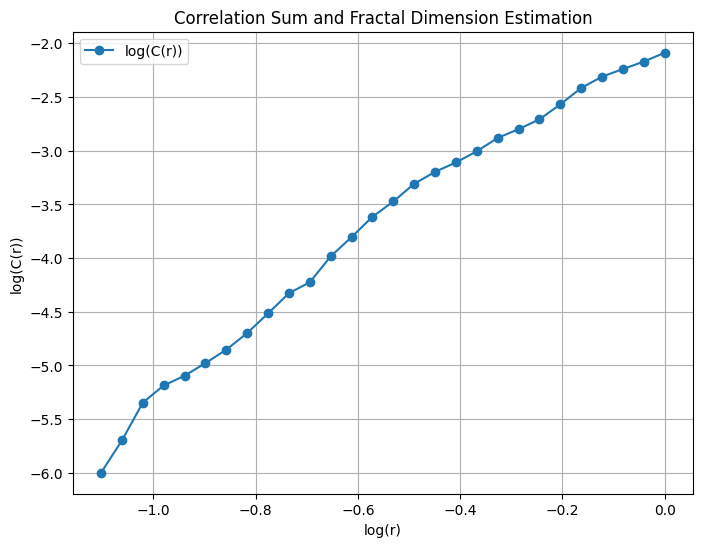

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import KDTree


def downsample(data, factor):
    """Downsample the data by a given factor."""
    return data[:, ::factor]


def correlation_sum_with_kdtree(embedded_data, r):
    """Compute the correlation sum using a KDTree."""
    tree = KDTree(embedded_data)
    count = tree.query_ball_point(embedded_data, r, return_length=True) - 1
    return np.sum(count) / (len(embedded_data) * (len(embedded_data) - 1))


def estimate_fractal_dimension(
    data, m=3, tau=1, r_min=0.01, r_max=1.0, num_r=50, downsample_factor=20
):
    """Estimate the fractal dimension using maximum slope between every three points."""
    # Downsample the data
    data = downsample(data, downsample_factor)

    # Time-delay embedding
    N, T = data.shape
    embedded_data = []
    for i in range(T - (m - 1) * tau):
        embedded_data.append(data[:, i : i + m * tau : tau].flatten())
    embedded_data = np.array(embedded_data)

    # Generate a range of radii
    r_values = np.logspace(np.log10(r_min), np.log10(r_max), num_r)
    correlation_sums = np.array(
        [correlation_sum_with_kdtree(embedded_data, r) for r in r_values]
    )

    # Log-log space
    log_r = np.log10(r_values)
    log_c = np.log10(correlation_sums)

    # Compute slopes for every three consecutive points
    slopes = []
    for i in range(len(log_r) - 2):
        slope = (log_c[i + 2] - log_c[i]) / (log_r[i + 2] - log_r[i])
        slopes.append(slope)

    # Find maximum slope
    max_slope = max(slopes)
    print(f"Estimated Fractal Dimension (max slope): {max_slope}")

    # Plot
    plt.figure(figsize=(8, 6))
    plt.plot(log_r, log_c, marker="o", label="log(C(r))")
    plt.xlabel("log(r)")
    plt.ylabel("log(C(r))")
    plt.title("Correlation Sum and Fractal Dimension Estimation")
    plt.legend()
    plt.grid(True)
    plt.show()

    return max_slope


# Example usage
# Simulate system
n = 30
g = 1
mu = 0
tf = 2000
Nt = 50000
t, X = simulate1(n, g, mu, tf=tf)

# Estimate fractal dimensio
# data = X[:, int(0.2 * Nt) :]  # Remove transient
dimension = estimate_fractal_dimension(data, m=3, tau=1, downsample_factor=20)